# Frame-Based vs. Temporal Modeling for False-Positive Reduction in Gaze-Based Exam Cheating Detection
**Mona Khalil & Ezza Razaq · MS Data Science**


## 1. Setup


In [2]:
#  CONFIG
import os, glob, time, random, warnings, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

CSV_PATH      = "/content/Students suspicious behaviors detection dataset_V1.csv"
SEEDS         = [0, 1, 2]
WINDOWS       = [10, 30, 60]       # RQ2
MAIN_W        = 30                 # window used for RQ3 + dashboard
TARGET_RECALL = 0.90
MAX_EPOCHS, PATIENCE, BATCH = 40, 5, 64
SPLIT         = (0.60, 0.20)       # train 60 %, val 20 %, test = remaining 20 % (chronological)

# Gaze / head-pose / eye-nose landmark signals
NUM_COLS = ["left_eye_x","left_eye_y","right_eye_x","right_eye_y","nose_tip_x","nose_tip_y",
            "head_pitch","head_yaw","head_roll","gazePoint_x","gazePoint_y",
            "pupil_left_x","pupil_left_y","pupil_right_x","pupil_right_y"]
# Pre-computed categorical gaze / head-pose labels
CAT_COLS = ["head_pose", "gaze_direction"]
C_MLP, C_LSTM, C_NORMAL, C_CHEAT = "#3b6e8f", "#a8573e", "#8a97a3", "#c08a3e"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#cfcfca", "grid.color": "#e7e7e3"})
DETERMINISTIC = True   # deterministic TF ops
if DETERMINISTIC:
    try: tf.config.experimental.enable_op_determinism()
    except Exception as e: print("Deterministic ops not enabled:", e)
HW = {"tensorflow": tf.__version__, "cpu": platform.processor() or platform.machine(), "cpu_count": os.cpu_count(),
      "gpus": [d.name for d in tf.config.list_physical_devices("GPU")]}
print("Hardware / software:", HW)

Hardware / software: {'tensorflow': '2.21.0', 'cpu': 'x86_64', 'cpu_count': 2, 'gpus': ['/physical_device:GPU:0']}


## 2. Load data and diagnostics


File: Students suspicious behaviors detection dataset_V1.csv
Shape: 5500 rows x 38 columns

Missing values per column (only columns with any):
head_pose          569
gaze_direction    1051

Class counts (0 = normal, 1 = cheating):
label
0    2881
1    2619

[Order] mean lag-1 autocorrelation: file order = 0.65, shuffled = 0.00
[Order] label runs: file order = 990, shuffled = 2757 (fewer = more blocky)
[Order] Neighbouring rows are similar, which is consistent with a time-ordered file, but it does NOT prove they are consecutive frames.
[Order] There is no student/session ID and no timestamp, so the windows below are EXPLORATORY row-order windows (state this as a limitation).

[Leak check] label rate by head_pose (NaN shown as 'missing'):
label         0     1
head_pose            
down          0   367
forward    2881  1055
left          0   227
missing       0   569
right         0   401

[Leak check] label rate by gaze_direction:
label              0     1
gaze_direction            
b

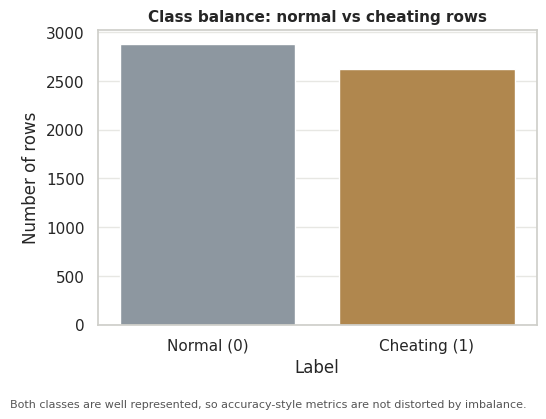

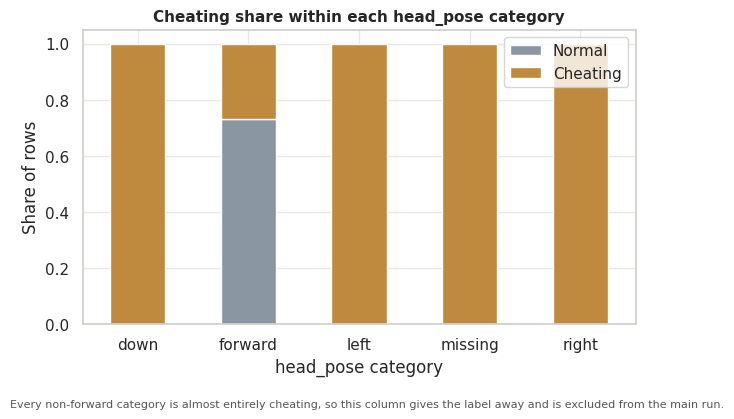

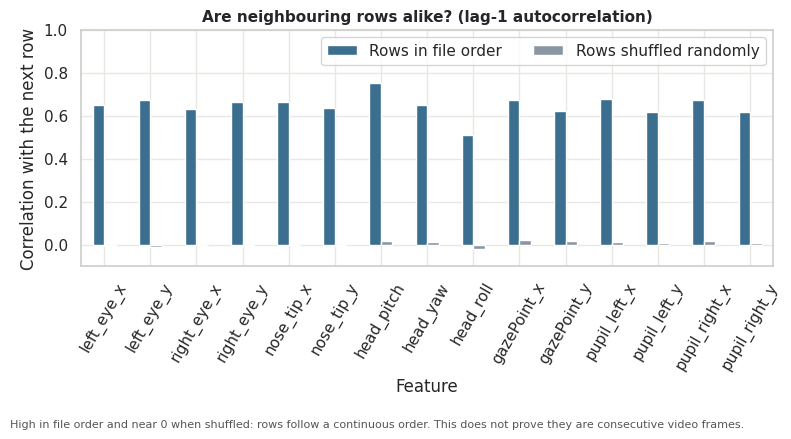

In [3]:
cands = [CSV_PATH] + glob.glob("/content/*uspicious*.csv") + glob.glob("*uspicious*.csv")
path = next(p for p in cands if os.path.exists(p))
df = pd.read_csv(path)
y_all = df["label"].values
print(f"File: {os.path.basename(path)}\nShape: {df.shape[0]} rows x {df.shape[1]} columns")
print("\nMissing values per column (only columns with any):")
print(df.isnull().sum()[df.isnull().sum() > 0].to_string())
print("\nClass counts (0 = normal, 1 = cheating):"); print(df["label"].value_counts().to_string())

# ---- Diagnostic 1: are rows in time order?
shuf = df.sample(frac=1, random_state=0).reset_index(drop=True)
ac = pd.DataFrame({"file order": [df[c].autocorr(1) for c in NUM_COLS],
                   "shuffled":   [shuf[c].autocorr(1) for c in NUM_COLS]}, index=NUM_COLS)
runs = int((df["label"] != df["label"].shift()).sum())
runs_shuf = int((shuf["label"] != shuf["label"].shift()).sum())
print(f"\n[Order] mean lag-1 autocorrelation: file order = {ac['file order'].mean():.2f}, shuffled = {ac['shuffled'].mean():.2f}")
print(f"[Order] label runs: file order = {runs}, shuffled = {runs_shuf} (fewer = more blocky)")
print("[Order] Neighbouring rows are similar, which is consistent with a time-ordered file, but it does NOT prove they are consecutive frames.")
print("[Order] There is no student/session ID and no timestamp, so the windows below are EXPLORATORY row-order windows (state this as a limitation).")
if ac["file order"].mean() < 0.3: print("[Order] WARNING: rows look shuffled; windows would not be meaningful at all - tell your supervisor.")

# Diagnostic 2: do the categorical columns give the label away?
print("\n[Leak check] label rate by head_pose (NaN shown as 'missing'):")
print(pd.crosstab(df["head_pose"].fillna("missing"), df["label"]).to_string())
print("\n[Leak check] label rate by gaze_direction:")
print(pd.crosstab(df["gaze_direction"].fillna("missing"), df["label"]).to_string())

def note(fig, text): fig.text(0.01, 0.01, text, fontsize=8, color="#555")

fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.countplot(x="label", data=df, ax=ax, palette=[C_NORMAL, C_CHEAT]); ax.set_xticklabels(["Normal (0)", "Cheating (1)"])
ax.set_xlabel("Label"); ax.set_ylabel("Number of rows"); ax.set_title("Class balance: normal vs cheating rows", fontweight="bold", fontsize=11)
note(fig, "Both classes are well represented, so accuracy-style metrics are not distorted by imbalance."); plt.tight_layout(rect=(0, .04, 1, 1)); plt.savefig("eda_class_balance.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ct = pd.crosstab(df["head_pose"].fillna("missing"), df["label"], normalize="index"); ct.columns = ["Normal", "Cheating"]
ct.plot(kind="bar", stacked=True, ax=ax, color=[C_NORMAL, C_CHEAT]); ax.tick_params(axis="x", rotation=0)
ax.set_xlabel("head_pose category"); ax.set_ylabel("Share of rows"); ax.set_title("Cheating share within each head_pose category", fontweight="bold", fontsize=11)
note(fig, "Every non-forward category is almost entirely cheating, so this column gives the label away and is excluded from the main run."); plt.tight_layout(rect=(0, .04, 1, 1)); plt.savefig("eda_head_pose.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.4))
ac.rename(columns={"file order": "Rows in file order", "shuffled": "Rows shuffled randomly"}).plot(kind="bar", ax=ax, color=[C_MLP, C_NORMAL])
ax.set_ylim(-0.1, 1.0); ax.legend(loc="upper right", ncol=2); ax.set_ylabel("Correlation with the next row"); ax.set_xlabel("Feature"); ax.tick_params(axis="x", rotation=60)
ax.set_title("Are neighbouring rows alike? (lag-1 autocorrelation)", fontweight="bold", fontsize=11)
note(fig, "High in file order and near 0 when shuffled: rows follow a continuous order. This does not prove they are consecutive video frames."); plt.tight_layout(rect=(0, .04, 1, 1)); plt.savefig("eda_order.png", dpi=200); plt.show()

## 3. Leak-free preprocessing


In [4]:
#15 **continuous** gaze / head-pose / eye-nose signals. The categorical `head_pose` and `gaze_direction` are tested only in the ablation (section 7).
def prepare(use_cat=False):
    """Chronological 60/20/20 split FIRST; imputer + scaler are fitted on the training part only."""
    X = df[NUM_COLS].apply(pd.to_numeric, errors="coerce")
    if use_cat:
        X = pd.concat([X, pd.get_dummies(df[CAT_COLS].fillna("missing").astype(str)).astype(float)], axis=1)
    names = list(X.columns); X = X.values.astype(float)
    n = len(X); a, b = int(n * SPLIT[0]), int(n * (SPLIT[0] + SPLIT[1]))
    med = np.nanmedian(X[:a], axis=0)
    X = np.where(np.isnan(X), med, X)
    sc = StandardScaler().fit(X[:a]); X = sc.transform(X)
    return dict(names=names, X=(X[:a], X[a:b], X[b:]), y=(y_all[:a], y_all[a:b], y_all[b:]))

def windows(X, y, W):
    """Windows are built INSIDE each split (no input overlap between train/val/test).
    Label = label of the last frame. Returns sequence input, last-frame input (for the MLP), labels."""
    seq = np.lib.stride_tricks.sliding_window_view(X, (W, X.shape[1]))[:, 0].astype(np.float32)
    return seq, X[W - 1:].astype(np.float32), y[W - 1:]

d = prepare(False)
print("Features used:", len(d["names"]), d["names"])
print("Rows  train/val/test:", [len(v) for v in d["X"]])
print("Cheating rate train/val/test:", [round(float(v.mean()), 3) for v in d["y"]])
rates = [float(v.mean()) for v in d["y"]]
if max(rates) - min(rates) > 0.2:
    print("\nWARNING: the cheating rate differs a lot between chronological blocks (rows come in session-like blocks).")
    print("         The validation-calibrated threshold may therefore not give exactly 90% recall on the test set;")
    print("         that is why Table I also reports the recall actually achieved and the FPR at exactly 90% recall.")

Features used: 15 ['left_eye_x', 'left_eye_y', 'right_eye_x', 'right_eye_y', 'nose_tip_x', 'nose_tip_y', 'head_pitch', 'head_yaw', 'head_roll', 'gazePoint_x', 'gazePoint_y', 'pupil_left_x', 'pupil_left_y', 'pupil_right_x', 'pupil_right_y']
Rows  train/val/test: [3300, 1100, 1100]
Cheating rate train/val/test: [0.54, 0.178, 0.584]

         The validation-calibrated threshold may therefore not give exactly 90% recall on the test set;
         that is why Table I also reports the recall actually achieved and the FPR at exactly 90% recall.


## 4. Metrics and models


In [5]:
#Threshold calibration, evaluation helpers and the two architectures (Frame MLP, Temporal LSTM). The seed is set before each model is built and the Keras session is cleared first.
def calibrate_threshold(y, p, target=TARGET_RECALL):
    """Highest threshold whose recall on (validation) data is >= target."""
    fpr, tpr, th = roc_curve(y, p); return float(th[np.argmax(tpr >= target)])

def fpr_at_recall(y, p, target=TARGET_RECALL):
    fpr, tpr, _ = roc_curve(y, p); return float(fpr[np.argmax(tpr >= target)])

def evaluate(y, p, thr):
    pred = (p >= thr).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    tn = int(((pred == 0) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return dict(recall=rec, fpr=fp / max(fp + tn, 1), precision=prec,
                f1=2 * prec * rec / max(prec + rec, 1e-9), acc=(tp + tn) / len(y))

In [6]:
def set_seed(s):
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)

def build_mlp(F):
    return models.Sequential([layers.Input(shape=(F,)), layers.Dense(64, activation="relu"), layers.Dropout(0.3),
                              layers.Dense(32, activation="relu"), layers.Dense(1, activation="sigmoid")])

def build_lstm(W, F, unroll=False):
    return models.Sequential([layers.Input(shape=(W, F)), layers.LSTM(64, unroll=unroll), layers.Dropout(0.3),
                              layers.Dense(32, activation="relu"), layers.Dense(1, activation="sigmoid")])

def fit_predict(kind, Xtr, ytr, Xva, yva, Xte, seed):
    """Train with early stopping on VALIDATION loss. Returns val probs, test probs, model, seconds, epochs."""
    tf.keras.backend.clear_session(); set_seed(seed)      # seed set before the model is built
    m = build_mlp(Xtr.shape[-1]) if kind == "MLP" else build_lstm(Xtr.shape[1], Xtr.shape[2])
    m.compile(optimizer="adam", loss="binary_crossentropy")
    es = callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    t0 = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=MAX_EPOCHS, batch_size=BATCH, callbacks=[es], verbose=0)
    secs = time.time() - t0
    return (m.predict(Xva, verbose=0).ravel(), m.predict(Xte, verbose=0).ravel(), m, secs, len(h.history["loss"]))

## 5. RQ1 and RQ2: FPR at 90 % recall for window lengths 10, 30, 60


In [7]:
KEPT = {}   # models/data kept for RQ3 + dashboard

def run_experiment(use_cat, wins, seeds, tag):
    D = prepare(use_cat); rows = []
    for W in wins:
        sTr, fTr, yTr = windows(D["X"][0], D["y"][0], W)
        sVa, fVa, yVa = windows(D["X"][1], D["y"][1], W)
        sTe, fTe, yTe = windows(D["X"][2], D["y"][2], W)
        for seed in seeds:
            for kind, (a, b, c) in {"Frame MLP": (fTr, fVa, fTe), "Temporal LSTM": (sTr, sVa, sTe)}.items():
                pv, pe, m, secs, ep = fit_predict("MLP" if kind == "Frame MLP" else "LSTM", a, yTr, b, yVa, c, seed)
                thr = calibrate_threshold(yVa, pv)                 # threshold from VALIDATION only
                r = evaluate(yTe, pe, thr)
                r.update(setting=tag, model=kind, W=W, seed=seed, auc=roc_auc_score(yTe, pe), thr=thr,
                         fpr_oracle90=fpr_at_recall(yTe, pe), epochs=ep, train_s=secs)
                rows.append(r)
                print(f"[{tag}] W={W:>2} seed={seed} {kind:13s} AUC={r['auc']:.3f} recall={r['recall']:.3f} FPR={r['fpr']:.3f} (ep={ep}, {secs:.0f}s)")
                if tag == "numeric" and W == MAIN_W and seed == seeds[0]:
                    KEPT[kind] = dict(model=m, thr=thr, Xtr=a, pv=pv, pe=pe, yTe=yTe,
                                      Xte=(fTe if kind == "Frame MLP" else sTe), yVa=yVa, Xva=(fVa if kind == "Frame MLP" else sVa))
    return pd.DataFrame(rows), D

# MAIN experiment: continuous gaze / head-pose signals only
res_main, D_main = run_experiment(False, WINDOWS, SEEDS, "numeric")

[numeric] W=10 seed=0 Frame MLP     AUC=0.849 recall=0.850 FPR=0.341 (ep=21, 12s)
[numeric] W=10 seed=0 Temporal LSTM AUC=0.780 recall=0.916 FPR=0.655 (ep=21, 11s)
[numeric] W=10 seed=1 Frame MLP     AUC=0.843 recall=0.913 FPR=0.526 (ep=25, 10s)
[numeric] W=10 seed=1 Temporal LSTM AUC=0.796 recall=0.866 FPR=0.474 (ep=23, 11s)
[numeric] W=10 seed=2 Frame MLP     AUC=0.837 recall=0.900 FPR=0.501 (ep=24, 10s)
[numeric] W=10 seed=2 Temporal LSTM AUC=0.777 recall=0.917 FPR=0.635 (ep=21, 10s)
[numeric] W=30 seed=0 Frame MLP     AUC=0.864 recall=0.872 FPR=0.343 (ep=40, 15s)
[numeric] W=30 seed=0 Temporal LSTM AUC=0.779 recall=0.961 FPR=0.688 (ep=24, 13s)
[numeric] W=30 seed=1 Frame MLP     AUC=0.862 recall=0.852 FPR=0.301 (ep=40, 15s)
[numeric] W=30 seed=1 Temporal LSTM AUC=0.730 recall=0.894 FPR=0.681 (ep=9, 6s)
[numeric] W=30 seed=2 Frame MLP     AUC=0.814 recall=0.824 FPR=0.357 (ep=10, 4s)
[numeric] W=30 seed=2 Temporal LSTM AUC=0.788 recall=0.961 FPR=0.688 (ep=24, 12s)
[numeric] W=60 seed

## 6. Tables and figures


TABLE I - frame MLP vs temporal LSTM (mean ± sd over seeds, test set)


,Setting,W,Model,FPR % (val-calibrated thr.),Recall % achieved,Precision,F1,AUC
0,numeric,10,Frame MLP,45.6 ± 10.0,88.8 ± 3.3,0.738,0.805,0.843 ± 0.006
1,numeric,10,Temporal LSTM,58.8 ± 9.9,90.0 ± 2.9,0.688,0.779,0.784 ± 0.010
2,numeric,30,Frame MLP,33.3 ± 2.9,84.9 ± 2.4,0.792,0.820,0.847 ± 0.028
3,numeric,30,Temporal LSTM,68.5 ± 0.4,93.9 ± 3.9,0.672,0.783,0.766 ± 0.031
4,numeric,60,Frame MLP,38.6 ± 12.8,85.4 ± 6.7,0.782,0.814,0.842 ± 0.011
5,numeric,60,Temporal LSTM,57.7 ± 11.0,88.1 ± 5.6,0.710,0.785,0.767 ± 0.020



EXPLORATORY DIAGNOSTIC (not a primary result)


,W,Model,"FPR % at exactly 90% recall (EXPLORATORY - uses test labels, not deployable)"
0,10,Frame MLP,48.3
1,10,Temporal LSTM,58.9
2,30,Frame MLP,44.3
3,30,Temporal LSTM,59.5
4,60,Frame MLP,47.3
5,60,Temporal LSTM,62.2



TABLE II - effect of window length (RQ2). Positive change = LSTM has HIGHER (worse) FPR.


,W,MLP FPR %,LSTM FPR %,FPR change (LSTM vs MLP): + = LSTM worse,MLP recall %,LSTM recall %
0,10,45.6,58.8,+29.0%,88.8,90.0
1,30,33.3,68.5,+105.6%,84.9,93.9
2,60,38.6,57.7,+49.4%,85.4,88.1



Plain-language reading (always read FPR together with recall):
  W=10: Frame MLP has the lower FPR (MLP 45.6% vs LSTM 58.8%), at recall MLP 88.8% vs LSTM 90.0%.
  W=30: Frame MLP has the lower FPR (MLP 33.3% vs LSTM 68.5%), at recall MLP 84.9% vs LSTM 93.9%.
  W=60: Frame MLP has the lower FPR (MLP 38.6% vs LSTM 57.7%), at recall MLP 85.4% vs LSTM 88.1%.


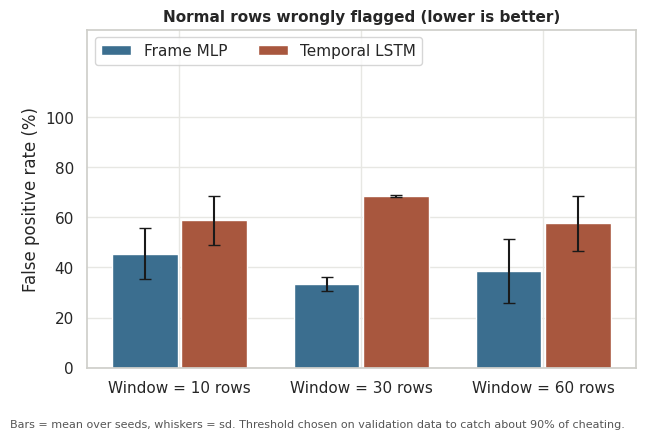

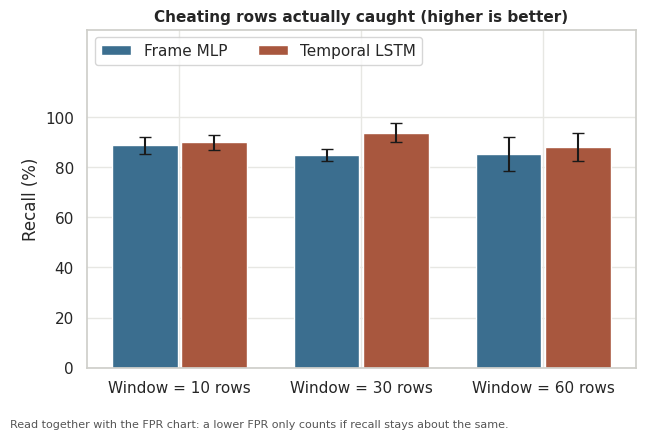

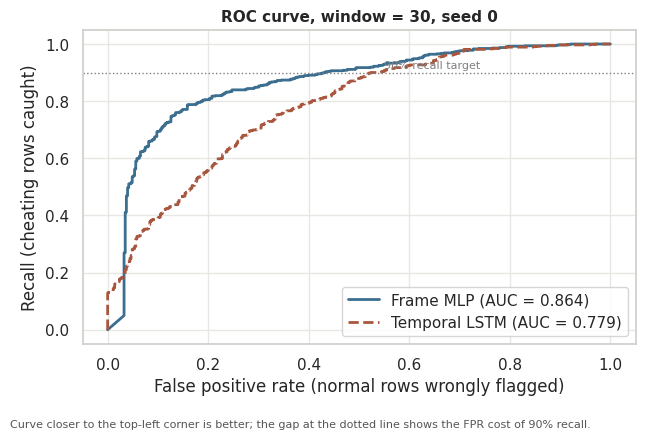

In [8]:
def summarise(res):
    g = res.groupby(["setting", "W", "model"])
    out = g.agg(auc=("auc", "mean"), auc_sd=("auc", "std"), fpr=("fpr", "mean"), fpr_sd=("fpr", "std"),
                recall=("recall", "mean"), recall_sd=("recall", "std"), precision=("precision", "mean"),
                f1=("f1", "mean"), fpr_oracle90=("fpr_oracle90", "mean")).reset_index().fillna(0)
    return out

def fmt(s):
    t = pd.DataFrame({"Setting": s["setting"], "W": s["W"], "Model": s["model"],
        "FPR % (val-calibrated thr.)": [f"{a*100:.1f} ± {b*100:.1f}" for a, b in zip(s["fpr"], s["fpr_sd"])],
        "Recall % achieved": [f"{a*100:.1f} ± {b*100:.1f}" for a, b in zip(s["recall"], s["recall_sd"])],
        "Precision": s["precision"].round(3), "F1": s["f1"].round(3),
        "AUC": [f"{a:.3f} ± {b:.3f}" for a, b in zip(s["auc"], s["auc_sd"])]})
    return t

sum_main = summarise(res_main)
table1 = fmt(sum_main)
print("TABLE I - frame MLP vs temporal LSTM (mean ± sd over seeds, test set)"); display(table1)

diag = pd.DataFrame({"W": sum_main["W"], "Model": sum_main["model"],
        "FPR % at exactly 90% recall (EXPLORATORY - uses test labels, not deployable)": (sum_main["fpr_oracle90"] * 100).round(1)})
print("\nEXPLORATORY DIAGNOSTIC (not a primary result)"); display(diag); diag.to_csv("diagnostic_oracle_fpr.csv", index=False)

# relative FPR change per window: NEGATIVE = LSTM has LOWER FPR; POSITIVE = LSTM is worse (higher FPR)
rel = []
for W in WINDOWS:
    a = sum_main[(sum_main.W == W) & (sum_main.model == "Frame MLP")].iloc[0]
    b = sum_main[(sum_main.W == W) & (sum_main.model == "Temporal LSTM")].iloc[0]
    rel.append({"W": W, "MLP FPR %": round(a.fpr * 100, 1), "LSTM FPR %": round(b.fpr * 100, 1),
                "FPR change (LSTM vs MLP): + = LSTM worse": f"{(b.fpr - a.fpr) / max(a.fpr, 1e-9) * 100:+.1f}%",
                "MLP recall %": round(a.recall * 100, 1), "LSTM recall %": round(b.recall * 100, 1)})
rel_df = pd.DataFrame(rel); print("\nTABLE II - effect of window length (RQ2). Positive change = LSTM has HIGHER (worse) FPR."); display(rel_df)
print("\nPlain-language reading (always read FPR together with recall):")
for r in rel:
    lo = "LSTM" if r["LSTM FPR %"] < r["MLP FPR %"] else "Frame MLP"
    print(f"  W={r['W']}: {lo} has the lower FPR (MLP {r['MLP FPR %']}% vs LSTM {r['LSTM FPR %']}%), at recall MLP {r['MLP recall %']}% vs LSTM {r['LSTM recall %']}%.")

# figures
def bars(col, sd, ylabel, title, fname, note):
    fig, ax = plt.subplots(figsize=(6.5, 4.4))
    for k, (kind, colr) in enumerate({"Frame MLP": C_MLP, "Temporal LSTM": C_LSTM}.items()):
        t = sum_main[sum_main.model == kind]
        ax.bar(np.arange(len(WINDOWS)) + k * 0.38 - 0.19, t[col] * 100, 0.36, yerr=t[sd] * 100, capsize=4, label=kind, color=colr)
    ax.set_xticks(range(len(WINDOWS))); ax.set_xticklabels([f"Window = {w} rows" for w in WINDOWS])
    ax.set_ylim(0, 135); ax.set_yticks(range(0, 101, 20)); ax.set_ylabel(ylabel); ax.set_title(title, fontweight="bold", fontsize=11); ax.legend(loc="upper left", ncol=2)
    fig.text(0.01, 0.01, note, fontsize=8, color="#555"); plt.tight_layout(rect=(0, .04, 1, 1)); plt.savefig(fname, dpi=200); plt.show()

bars("fpr", "fpr_sd", "False positive rate (%)", "Normal rows wrongly flagged (lower is better)", "fig_fpr.png",
     "Bars = mean over seeds, whiskers = sd. Threshold chosen on validation data to catch about 90% of cheating.")
bars("recall", "recall_sd", "Recall (%)", "Cheating rows actually caught (higher is better)", "fig_recall.png",
     "Read together with the FPR chart: a lower FPR only counts if recall stays about the same.")
fig, ax = plt.subplots(figsize=(6.5, 4.4))
for kind, colr, ls in [("Frame MLP", C_MLP, "-"), ("Temporal LSTM", C_LSTM, "--")]:
    K = KEPT[kind]; f, t, _ = roc_curve(K["yTe"], K["pe"])
    ax.plot(f, t, color=colr, ls=ls, lw=2, label=f"{kind} (AUC = {roc_auc_score(K['yTe'], K['pe']):.3f})")
ax.axhline(TARGET_RECALL, color="grey", ls=":", lw=1); ax.text(0.55, TARGET_RECALL + 0.015, "90% recall target", color="grey", fontsize=8)
ax.set_xlabel("False positive rate (normal rows wrongly flagged)"); ax.set_ylabel("Recall (cheating rows caught)")
ax.set_title(f"ROC curve, window = {MAIN_W}, seed {SEEDS[0]}", fontweight="bold", fontsize=11); ax.legend(loc="lower right")
fig.text(0.01, 0.01, "Curve closer to the top-left corner is better; the gap at the dotted line shows the FPR cost of 90% recall.", fontsize=8, color="#555")
plt.tight_layout(rect=(0, .04, 1, 1)); plt.savefig("fig_roc.png", dpi=200); plt.show()

res_main.to_csv("all_results.csv", index=False); table1.to_csv("table1_fpr.csv", index=False); rel_df.to_csv("table2_windows.csv", index=False)

## 7. Ablation: add the categorical columns


In [9]:
# ABLATION: adding the pre-computed categorical head_pose / gaze_direction (one-hot). These columns almost define the label
# (see leak check), so this shows how much of the result depends on them.
res_cat, _ = run_experiment(True, [MAIN_W], SEEDS, "numeric+categorical")
sum_cat = summarise(res_cat); print("\nABLATION - with categorical head_pose / gaze_direction (W=%d)" % MAIN_W); display(fmt(sum_cat))
pd.concat([res_main, res_cat]).to_csv("all_results.csv", index=False)
fmt(sum_cat).to_csv("table_ablation_categorical.csv", index=False)

[numeric+categorical] W=30 seed=0 Frame MLP     AUC=0.909 recall=0.695 FPR=0.000 (ep=18, 7s)
[numeric+categorical] W=30 seed=0 Temporal LSTM AUC=0.904 recall=0.754 FPR=0.047 (ep=14, 8s)
[numeric+categorical] W=30 seed=1 Frame MLP     AUC=0.917 recall=0.701 FPR=0.000 (ep=18, 8s)
[numeric+categorical] W=30 seed=1 Temporal LSTM AUC=0.888 recall=0.741 FPR=0.033 (ep=12, 7s)
[numeric+categorical] W=30 seed=2 Frame MLP     AUC=0.901 recall=0.509 FPR=0.000 (ep=27, 10s)
[numeric+categorical] W=30 seed=2 Temporal LSTM AUC=0.911 recall=0.771 FPR=0.126 (ep=11, 7s)

ABLATION - with categorical head_pose / gaze_direction (W=30)


,Setting,W,Model,FPR % (val-calibrated thr.),Recall % achieved,Precision,F1,AUC
0,numeric+categorical,30,Frame MLP,0.0 ± 0.0,63.5 ± 10.9,1.000,0.773,0.909 ± 0.008
1,numeric+categorical,30,Temporal LSTM,6.8 ± 5.0,75.5 ± 1.5,0.944,0.839,0.901 ± 0.012


In [10]:
#  ROBUSTNESS CHECK (separate from the main result): mask detector-failure zeros
df_orig = df.copy(); df_m = df.copy()
patterns = {"head angles": ["head_pitch", "head_yaw", "head_roll"],
            "gaze + pupil": ["gazePoint_x", "gazePoint_y", "pupil_left_x", "pupil_left_y", "pupil_right_x", "pupil_right_y"],
            "eye + nose landmarks": ["left_eye_x", "left_eye_y", "right_eye_x", "right_eye_y", "nose_tip_x", "nose_tip_y"]}
for name, cols in patterns.items():
    m = (df_m[cols] == 0).all(axis=1)                    # ALL columns of the group are exactly 0 = tracker lost the face/eyes
    df_m.loc[m, cols] = np.nan                           # becomes missing -> train-median imputation inside prepare()
    print(f"{name}: {int(m.sum())} rows masked (cheating share of those rows: {df_orig.loc[m, 'label'].mean():.1%})")
print("Rows kept:", len(df_m), "(nothing is dropped, so the row order is unchanged)")

df = df_m
try:
    res_masked, _ = run_experiment(False, WINDOWS, SEEDS, "numeric_masked")
finally:
    df = df_orig                                         # restoring the original data

sum_masked = summarise(res_masked)
a = sum_main.set_index(["W", "model"]); b = sum_masked.set_index(["W", "model"])
cmp = pd.DataFrame({"FPR % original": (a["fpr"] * 100).round(1), "FPR % masked": (b["fpr"] * 100).round(1),
                    "Recall % original": (a["recall"] * 100).round(1), "Recall % masked": (b["recall"] * 100).round(1),
                    "AUC original": a["auc"].round(3), "AUC masked": b["auc"].round(3)}).reset_index()
print("\nROBUSTNESS TABLE - original data vs. detector-failure zeros masked (mean over seeds, test set)"); display(cmp)
print("\nPlain-language reading:")
for W in WINDOWS:
    for tag, s in (("original", a), ("masked", b)):
        lo = "Frame MLP" if s.loc[(W, "Frame MLP"), "fpr"] < s.loc[(W, "Temporal LSTM"), "fpr"] else "Temporal LSTM"
        print(f"  W={W} {tag:8s}: {lo} has the lower FPR (MLP {s.loc[(W,'Frame MLP'),'fpr']*100:.1f}% vs LSTM {s.loc[(W,'Temporal LSTM'),'fpr']*100:.1f}%)")
cmp.to_csv("table_robustness_masked_zeros.csv", index=False); res_masked.to_csv("all_results_masked.csv", index=False)

head angles: 569 rows masked (cheating share of those rows: 100.0%)
gaze + pupil: 1051 rows masked (cheating share of those rows: 61.5%)
eye + nose landmarks: 136 rows masked (cheating share of those rows: 100.0%)
Rows kept: 5500 (nothing is dropped, so the row order is unchanged)
[numeric_masked] W=10 seed=0 Frame MLP     AUC=0.798 recall=0.914 FPR=0.566 (ep=38, 15s)
[numeric_masked] W=10 seed=0 Temporal LSTM AUC=0.718 recall=0.891 FPR=0.608 (ep=15, 8s)
[numeric_masked] W=10 seed=1 Frame MLP     AUC=0.819 recall=0.880 FPR=0.423 (ep=40, 15s)
[numeric_masked] W=10 seed=1 Temporal LSTM AUC=0.717 recall=0.869 FPR=0.601 (ep=18, 9s)
[numeric_masked] W=10 seed=2 Frame MLP     AUC=0.785 recall=0.916 FPR=0.615 (ep=37, 14s)
[numeric_masked] W=10 seed=2 Temporal LSTM AUC=0.704 recall=0.826 FPR=0.570 (ep=15, 8s)
[numeric_masked] W=30 seed=0 Frame MLP     AUC=0.801 recall=0.908 FPR=0.557 (ep=40, 15s)
[numeric_masked] W=30 seed=0 Temporal LSTM AUC=0.687 recall=0.726 FPR=0.431 (ep=10, 5s)
[numeric_m

,W,model,FPR % original,FPR % masked,Recall % original,Recall % masked,AUC original,AUC masked
0,10,Frame MLP,45.6,53.5,88.8,90.3,0.843,0.800
1,10,Temporal LSTM,58.8,59.3,90.0,86.2,0.784,0.713
2,30,Frame MLP,33.3,47.1,84.9,79.8,0.847,0.759
3,30,Temporal LSTM,68.5,49.4,93.9,75.4,0.766,0.661
4,60,Frame MLP,38.6,44.0,85.4,72.8,0.842,0.723
5,60,Temporal LSTM,57.7,61.3,88.1,79.0,0.767,0.614



Plain-language reading:
  W=10 original: Frame MLP has the lower FPR (MLP 45.6% vs LSTM 58.8%)
  W=10 masked  : Frame MLP has the lower FPR (MLP 53.5% vs LSTM 59.3%)
  W=30 original: Frame MLP has the lower FPR (MLP 33.3% vs LSTM 68.5%)
  W=30 masked  : Frame MLP has the lower FPR (MLP 47.1% vs LSTM 49.4%)
  W=60 original: Frame MLP has the lower FPR (MLP 38.6% vs LSTM 57.7%)
  W=60 masked  : Frame MLP has the lower FPR (MLP 44.0% vs LSTM 61.3%)


## 8. RQ3: complexity and quantization (W = 30, first seed)


In [11]:
# RQ3: complexity and quantization (W = MAIN_W, first seed)
def lat_stats(ts):
    ts = np.asarray(ts); return dict(mean=float(ts.mean()), median=float(np.median(ts)), p95=float(np.percentile(ts, 95)))

def approx_macs(kind, W, F, H=64):
    """ESTIMATE of multiply-accumulates per prediction (ignores activations / element-wise ops)."""
    dense = H * 32 + 32
    return F * 64 + 64 * 32 + 32 if kind == "Frame MLP" else W * 4 * (F * H + H * H) + dense

def keras_timing(m, X, n=200):
    """End-to-end single-sample latency (batch = 1): input -> model call -> NumPy output. Forced onto CPU like TFLite."""
    with tf.device("/CPU:0"):
        for k in range(20): m(X[k:k+1], training=False).numpy()               # warm-up
        T = []
        for k in range(min(n, len(X))):
            t0 = time.perf_counter(); float(m(X[k:k+1], training=False).numpy()[0, 0]); T.append((time.perf_counter() - t0) * 1000)
    return lat_stats(T)

def convert(src, mode, rep=None):
    c = tf.lite.TFLiteConverter.from_keras_model(src)
    if mode in ("dynamic", "int8"): c.optimizations = [tf.lite.Optimize.DEFAULT]
    if mode == "int8":                                                          # full-integer: needs representative data
        def gen():
            for x in rep[:300]: yield [x[None].astype(np.float32)]
        c.representative_dataset = gen
        c.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        c.inference_input_type = tf.int8; c.inference_output_type = tf.int8
    return c.convert()

def tflite_run(blob, X):
    """Predict every sample one by one. Latency per sample = set input + invoke + read output (+ (de)quantization)."""
    it = tf.lite.Interpreter(model_content=blob); it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    def one(x):
        x = x[None].astype(np.float32)
        if inp["dtype"] in (np.int8, np.uint8):
            sc, zp = inp["quantization"]
            if sc == 0: raise ValueError("input quantization scale is 0")
            x = np.clip(np.round(x / sc + zp), np.iinfo(inp["dtype"]).min, np.iinfo(inp["dtype"]).max)
        it.set_tensor(inp["index"], x.astype(inp["dtype"])); it.invoke()
        z = it.get_tensor(out["index"])
        if out["dtype"] in (np.int8, np.uint8):
            sc, zp = out["quantization"]; z = (z.astype(np.float32) - zp) * sc
        return float(np.asarray(z).reshape(-1)[0])
    for x in X[:20]: one(x)
    P, T = np.empty(len(X)), []
    for k, x in enumerate(X):
        t0 = time.perf_counter(); P[k] = one(x); T.append((time.perf_counter() - t0) * 1000)
    return P, lat_stats(T)

def add_rows(rows, kind, variant, pv, pe, lat, size_kb, kthr, K, maxdiff=None):
    yv, yt = K["yVa"], K["yTe"]; own = calibrate_threshold(yv, pv); auc = roc_auc_score(yt, pe)
    for tname, thr in [("Keras val-threshold", kthr), ("Own val-threshold", own)]:
        r = evaluate(yt, pe, thr)
        rows.append({"Model": kind, "Variant": variant, "Threshold": tname, "Thr value": round(thr, 4),
                     "FPR %": round(r["fpr"] * 100, 1), "Recall %": round(r["recall"] * 100, 1), "Precision": round(r["precision"], 3),
                     "F1": round(r["f1"], 3), "Accuracy": round(r["acc"], 3), "AUC": round(auc, 4), "Size KB": round(size_kb, 1),
                     "Latency mean ms": round(lat["mean"], 3), "Latency median ms": round(lat["median"], 3), "Latency p95 ms": round(lat["p95"], 3),
                     "Max |prob - Keras|": "-" if maxdiff is None else round(maxdiff, 4), "Status": "ok"})

VARIANTS = [("TFLite FP32", "fp32"), ("TFLite dynamic-range INT8", "dynamic"), ("TFLite full-integer INT8", "int8")]
comp_rows, quant_rows = [], []
for kind in ["Frame MLP", "Temporal LSTM"]:
    K = KEPT[kind]; m = K["model"]; Xte, Xva, Xtr, kthr = K["Xte"], K["Xva"], K["Xtr"], K["thr"]
    sel = res_main[(res_main.model == kind) & (res_main.W == MAIN_W) & (res_main.seed == SEEDS[0])].iloc[0]
    path = f"{kind.replace(' ', '_')}.keras"; m.save(path); keras_kb = os.path.getsize(path) / 1024
    macs = approx_macs(kind, MAIN_W, Xte.shape[-1])
    comp_rows.append({"Model": kind, "Parameters": int(m.count_params()), "Approx MACs (estimate)": int(macs), "Approx FLOPs (estimate = 2 x MACs)": int(2 * macs),
                      "Epochs run": int(sel.epochs), "Train time s": round(float(sel.train_s), 1), "FP32 weights KB (params x 4 B)": round(m.count_params() * 4 / 1024, 1), "Keras file KB (also stores optimizer + metadata, do NOT use for size claims)": round(keras_kb, 1)})
    add_rows(quant_rows, kind, "Keras FP32", K["pv"], K["pe"], keras_timing(m, Xte), m.count_params() * 4 / 1024, kthr, K)   # Keras size = FP32 weights only
    src = m
    if kind == "Temporal LSTM":      # LSTM -> TFLite is fragile; convert an UNROLLED twin that has identical weights
        try:
            src = build_lstm(Xte.shape[1], Xte.shape[2], unroll=True); src.set_weights(m.get_weights())
        except Exception as e:
            print("Unrolled twin failed, using the original LSTM:", e); src = m
    for label, mode in VARIANTS:     # each conversion is independent: one failure never erases the others
        try:
            blob = convert(src, mode, Xtr)
            pv, _ = tflite_run(blob, Xva); pe, lat = tflite_run(blob, Xte)
            add_rows(quant_rows, kind, label, pv, pe, lat, len(blob) / 1024, kthr, K, maxdiff=float(np.abs(pe - K["pe"]).max()))
        except Exception as e:
            msg = f"{type(e).__name__}: {str(e)[:200]}"; print(f"[{kind}] {label} FAILED -> {msg}")
            quant_rows.append({"Model": kind, "Variant": label, "Threshold": "-", "Status": "FAILED/UNSUPPORTED: " + msg})

comp_df = pd.DataFrame(comp_rows); quant_df = pd.DataFrame(quant_rows).fillna("-")
quant_main = quant_df[quant_df["Threshold"] != "Own val-threshold"].reset_index(drop=True)
quant_own = quant_df[quant_df["Threshold"] != "Keras val-threshold"].reset_index(drop=True)
print("NOTE: compare latency only WITHIN the TFLite rows. Keras (Python/eager) vs TFLite (compiled interpreter) differs because of the runtime, not because of quantization.")
print("NOTE: Keras size = FP32 weights (params x 4 bytes); TFLite size = the converted file.")
print("Hardware:", HW, "| latency = end-to-end single sample (batch 1), after 20 warm-up calls, Keras forced on CPU")
print(f"\nTABLE III-a - complexity (W={MAIN_W}, seed {SEEDS[0]}; MACs/FLOPs are estimates)"); display(comp_df)
print("\nTABLE III-b - every variant evaluated with the Keras model's validation threshold"); display(quant_main)
print("\nTABLE III-c - every variant with its OWN validation-calibrated threshold (never test-tuned)"); display(quant_own)
print("\nSanity check: 'Max |prob - Keras|' for TFLite FP32 should be tiny (about 1e-5); if not, the converted model differs from the Keras model.")
comp_df.to_csv("table3a_complexity.csv", index=False); quant_df.to_csv("table3b_quantization.csv", index=False)

Saved artifact at '/tmp/tmptdubf7lt'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 15), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139613160450256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139613317976848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139615681835664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139613160556112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139613160570704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139613160555536: TensorSpec(shape=(), dtype=tf.resource, name=None)
Saved artifact at '/tmp/tmphnp1_lw1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 15), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139613160450256: TensorSpec(

,Model,Parameters,Approx MACs (estimate),Approx FLOPs (estimate = 2 x MACs),Epochs run,Train time s,FP32 weights KB (params x 4 B),"Keras file KB (also stores optimizer + metadata, do NOT use for size claims)"
0,Frame MLP,3137,3040,6080,40,15.1,12.3,63.8
1,Temporal LSTM,22593,608800,1217600,24,12.8,88.3,295.3



TABLE III-b - every variant evaluated with the Keras model's validation threshold


,Model,Variant,Threshold,Thr value,FPR %,Recall %,Precision,F1,Accuracy,AUC,Size KB,Latency mean ms,Latency median ms,Latency p95 ms,Max |prob - Keras|,Status
0,Frame MLP,Keras FP32,Keras val-threshold,0.5657,34.3,87.2,0.792,0.830,0.786,0.8641,12.3,4.844,4.731,5.612,-,ok
1,Frame MLP,TFLite FP32,Keras val-threshold,0.5657,34.3,87.2,0.792,0.830,0.786,0.8644,14.4,0.006,0.006,0.006,0.0,ok
2,Frame MLP,TFLite dynamic-range INT8,Keras val-threshold,0.5657,34.3,87.1,0.792,0.829,0.785,0.8644,8.8,0.013,0.014,0.017,0.0078,ok
3,Frame MLP,TFLite full-integer INT8,Keras val-threshold,0.5657,34.0,86.9,0.793,0.829,0.785,0.8691,8.0,0.020,0.019,0.023,0.2791,ok
4,Temporal LSTM,Keras FP32,Keras val-threshold,0.1423,68.8,96.1,0.677,0.794,0.701,0.7789,88.3,10.746,10.535,11.908,-,ok
5,Temporal LSTM,TFLite FP32,Keras val-threshold,0.1423,68.8,96.1,0.677,0.794,0.701,0.7789,173.0,0.205,0.201,0.241,0.0,ok
6,Temporal LSTM,TFLite dynamic-range INT8,Keras val-threshold,0.1423,68.5,96.3,0.678,0.795,0.703,0.7795,114.5,0.096,0.088,0.132,0.0245,ok
7,Temporal LSTM,TFLite full-integer INT8,Keras val-threshold,0.1423,68.5,96.7,0.679,0.798,0.706,0.7822,176.0,0.111,0.106,0.128,0.5988,ok



TABLE III-c - every variant with its OWN validation-calibrated threshold (never test-tuned)


,Model,Variant,Threshold,Thr value,FPR %,Recall %,Precision,F1,Accuracy,AUC,Size KB,Latency mean ms,Latency median ms,Latency p95 ms,Max |prob - Keras|,Status
0,Frame MLP,Keras FP32,Own val-threshold,0.5657,34.3,87.2,0.792,0.830,0.786,0.8641,12.3,4.844,4.731,5.612,-,ok
1,Frame MLP,TFLite FP32,Own val-threshold,0.5657,34.3,87.2,0.792,0.830,0.786,0.8644,14.4,0.006,0.006,0.006,0.0,ok
2,Frame MLP,TFLite dynamic-range INT8,Own val-threshold,0.5663,34.3,87.1,0.792,0.829,0.785,0.8644,8.8,0.013,0.014,0.017,0.0078,ok
3,Frame MLP,TFLite full-integer INT8,Own val-threshold,0.5195,41.5,89.6,0.764,0.824,0.771,0.8691,8.0,0.020,0.019,0.023,0.2791,ok
4,Temporal LSTM,Keras FP32,Own val-threshold,0.1423,68.8,96.1,0.677,0.794,0.701,0.7789,88.3,10.746,10.535,11.908,-,ok
5,Temporal LSTM,TFLite FP32,Own val-threshold,0.1423,68.8,96.1,0.677,0.794,0.701,0.7789,173.0,0.205,0.201,0.241,0.0,ok
6,Temporal LSTM,TFLite dynamic-range INT8,Own val-threshold,0.1433,68.3,96.3,0.678,0.796,0.704,0.7795,114.5,0.096,0.088,0.132,0.0245,ok
7,Temporal LSTM,TFLite full-integer INT8,Own val-threshold,0.1562,67.6,96.3,0.681,0.797,0.707,0.7822,176.0,0.111,0.106,0.128,0.5988,ok



Sanity check: 'Max |prob - Keras|' for TFLite FP32 should be tiny (about 1e-5); if not, the converted model differs from the Keras model.


## 9. Dashboard


In [12]:
!pip install -q gradio

In [13]:
import gradio as gr

# switches for the Simulator tab
SHOW_HEAD_GAZE = True    # the head picture and the gaze-on-screen picture
SHOW_TIMELINE = False    # the line chart of the whole window
SHOW_MOTION = SHOW_HEAD_GAZE or SHOW_TIMELINE

names = D_main["names"]; WIN = MAIN_W
KM, KL = KEPT["Frame MLP"], KEPT["Temporal LSTM"]
Xseq, yte = KL["Xte"], KL["yTe"]
IDX = {k: names.index(k) for k in ["head_yaw", "head_pitch", "gazePoint_x", "gazePoint_y"]}
smain = sum_main[sum_main.W == MAIN_W]
m_ = smain[smain.model == "Frame MLP"].iloc[0]; l_ = smain[smain.model == "Temporal LSTM"].iloc[0]
winner = "Frame MLP" if m_.fpr < l_.fpr else "Temporal LSTM"
wr, orr = (m_.recall, l_.recall) if winner == "Frame MLP" else (l_.recall, m_.recall)
n_tr, n_va, n_te = [len(v) for v in D_main["X"]]

INK, MUTED, LINE, PAPER = "#1f2933", "#6b7280", "#d9d9d4", "#f7f7f4"
FONT = "font-family:system-ui,-apple-system,Segoe UI,sans-serif;"

def stat(label, value, note, accent):
    return (f"<div style='{FONT}flex:1;min-width:190px;padding:14px 16px;background:#fff;border:1px solid {LINE};border-left:4px solid {accent};border-radius:6px'>"
            f"<div style='font-size:11px;color:{MUTED};text-transform:uppercase;letter-spacing:.06em'>{label}</div>"
            f"<div style='font-size:26px;font-weight:700;color:{INK};margin:3px 0'>{value}</div>"
            f"<div style='font-size:12px;color:{MUTED};line-height:1.35'>{note}</div></div>")

def card(kind, title, body):
    pal = {"flag": ("#f6e8e3", "#7a3524", "#e3c4b9"), "clear": ("#e9f0ea", "#2e5a3b", "#c5d9c9")}[kind]
    return (f"<div style='{FONT}padding:14px 16px;border-radius:6px;background:{pal[0]};color:{pal[1]};border:1px solid {pal[2]}'>"
            f"<div style='font-size:16px;font-weight:700'>{title}</div><div style='font-size:13px;margin-top:4px'>{body}</div></div>")

head = (f"<div style='{FONT}padding:4px 0 14px 0;border-bottom:1px solid {LINE}'>"
        f"<div style='font-size:22px;font-weight:700;color:{INK}'>Frame-based vs. temporal modeling for exam-cheating detection</div>"
        f"<div style='font-size:13px;color:{MUTED};margin-top:4px'>Gaze and head-pose signals &middot; Frame MLP vs. temporal LSTM &middot; Mona Khalil and Ezza Razaq, MS Data Science</div></div>")
s1 = stat("Dataset", f"{len(df):,} rows", f"{len(names)} gaze / head-pose features. Split {n_tr} train / {n_va} validation / {n_te} test.", "#8a97a3")
s2 = stat(f"Frame MLP (window {WIN})", f"{m_.fpr*100:.1f}% FPR", f"Recall {m_.recall*100:.1f}%, AUC {m_.auc:.3f}", C_MLP)
s3 = stat(f"Temporal LSTM (window {WIN})", f"{l_.fpr*100:.1f}% FPR", f"Recall {l_.recall*100:.1f}%, AUC {l_.auc:.3f}", C_LSTM)
s4 = stat("Lower FPR", winner, f"Recall {wr*100:.1f}% vs {orr*100:.1f}% for the other model. Mean of {len(SEEDS)} seeds, test set.", "#c08a3e")

def fig_block(title, text, path):
    gr.Markdown(f"**{title}**  \n{text}")
    gr.Image(path, show_label=False, interactive=False)

def draw_motion(base, seq, k, nframes):
    k = int(k) - 1; W_ = len(seq); nframes = int(nframes)
    iy, ip, ix, ig = IDX["head_yaw"], IDX["head_pitch"], IDX["gazePoint_x"], IDX["gazePoint_y"]
    ratios = ([1, 1.25] if SHOW_HEAD_GAZE else []) + ([2.7] if SHOW_TIMELINE else [])
    fig = plt.figure(figsize=(sum(ratios) * 2.4, 3.6)); gs = fig.add_gridspec(1, len(ratios), width_ratios=ratios); j = 0
    if SHOW_HEAD_GAZE:
        a1, a2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]); j = 2
        yaw, pit = seq[k, iy], seq[k, ip]
        nx, ny = np.clip(yaw, -4, 4) * 0.2, np.clip(pit, -4, 4) * 0.2
        a1.add_patch(plt.Circle((0, 0), 1, fc="#f1f0ec", ec="#8a97a3", lw=1.6))
        for sx in (-0.38, 0.38): a1.add_patch(plt.Circle((sx + nx * 0.5, 0.28 + ny * 0.5), 0.09, fc="#1f2933"))
        a1.plot([nx * 0.4, nx], [ny * 0.4 - 0.05, ny - 0.05], color=C_LSTM, lw=3, solid_capstyle="round"); a1.plot([nx], [ny - 0.05], "o", color=C_LSTM, ms=9)
        a1.plot([-0.4, 0.4], [-0.55 + ny * 0.2, -0.55 + ny * 0.2], color="#8a97a3", lw=2)
        a1.set_xlim(-1.3, 1.3); a1.set_ylim(-1.3, 1.3); a1.set_aspect("equal"); a1.axis("off")
        a1.set_title(f"Head, row {k+1}\nturn {yaw:+.1f}\u03c3, tilt {pit:+.1f}\u03c3", fontsize=9.5, fontweight="bold")
        a2.add_patch(plt.Rectangle((0, 0), 1, 1, fc="#fbfbf9", ec="#8a97a3", lw=1.6))
        px = np.clip(0.5 + seq[:k + 1, ix] / 5, 0.03, 0.97); py = np.clip(0.5 + seq[:k + 1, ig] / 5, 0.03, 0.97)
        t0 = max(0, k - 8); a2.plot(px[t0:], py[t0:], color="#8a97a3", lw=1, alpha=.8); a2.plot(px[t0:-1], py[t0:-1], "o", color="#8a97a3", ms=3, alpha=.7)
        a2.plot([px[-1]], [py[-1]], "o", color=C_LSTM, ms=11); a2.set_xlim(-0.05, 1.05); a2.set_ylim(1.05, -0.05); a2.set_aspect("equal"); a2.axis("off")
        a2.set_title(f"Gaze on screen, row {k+1}\n(grey trail = last 8 rows)", fontsize=9.5, fontweight="bold")
    if SHOW_TIMELINE:
        a3 = fig.add_subplot(gs[0, j]); x = np.arange(1, W_ + 1)
        for key, col, lab in [(iy, C_MLP, "head yaw"), (ip, C_NORMAL, "head pitch"), (ix, C_LSTM, "gaze x"), (ig, C_CHEAT, "gaze y")]:
            a3.plot(x, base[:, key], color=col, lw=1, ls="--", alpha=.45); a3.plot(x, seq[:, key], color=col, lw=1.8, label=lab)
        if nframes < W_ or np.abs(seq - base).max() > 0: a3.axvspan(W_ - nframes + 0.5, W_ + 0.5, color="#c08a3e", alpha=.13)
        a3.axvline(k + 1, color="#1f2933", lw=1.2); a3.set_xlim(0.5, W_ + 0.5)
        a3.set_xlabel("Row in the window (oldest to newest)"); a3.set_ylabel("Signal (\u03c3 from average)")
        a3.set_title("Whole window over time (dashed = original, solid = shifted)", fontsize=9.5, fontweight="bold")
        a3.legend(loc="upper left", ncol=4, fontsize=8, frameon=False)
    fig.subplots_adjust(left=0.01 if not SHOW_TIMELINE else 0.01, right=0.99, wspace=0.18, bottom=0.2, top=0.82); plt.close(fig); return fig

def simulate(i, k, yaw, pitch, gx, gy, nframes, calibrated):
    i = int(i); nframes = int(nframes); base = Xseq[i].copy(); seq = base.copy()
    for key, sh in [("head_yaw", yaw), ("head_pitch", pitch), ("gazePoint_x", gx), ("gazePoint_y", gy)]:
        seq[-nframes:, IDX[key]] += sh                      # shift only the last `nframes` rows (copy: originals untouched)
    pm = float(KM["model"].predict(seq[-1:], verbose=0)[0, 0]); pl = float(KL["model"].predict(seq[None], verbose=0)[0, 0])
    tm, tl = (KM["thr"], KL["thr"]) if calibrated else (0.5, 0.5)
    gt = card("flag", "Actual label: cheating", "Ground truth for this test window") if yte[i] == 1 else card("clear", "Actual label: normal", "Ground truth for this test window")
    def pred(name, p, t):
        kind = "flag" if p >= t else "clear"
        return card(kind, ("Flagged" if p >= t else "Not flagged") + f" by {name}", f"Risk score {p*100:.1f}% against threshold {t*100:.1f}%")
    fig, ax = plt.subplots(figsize=(6, 2.9))
    bars_ = ax.barh(["Temporal LSTM", "Frame MLP"], [pl * 100, pm * 100], color=[C_LSTM, C_MLP], height=.5)
    ax.axvline(tm * 100, color=C_MLP, ls="--", lw=1.5); ax.axvline(tl * 100, color=C_LSTM, ls=":", lw=1.8)
    ax.set_xlim(0, 100); ax.set_xlabel("Risk score (%)")
    ax.set_title("Risk score vs. decision threshold (dashed = MLP, dotted = LSTM)", fontweight="bold", fontsize=9.5)
    for b in bars_: ax.text(min(b.get_width() + 1.5, 88), b.get_y() + b.get_height() / 2, f"{b.get_width():.1f}%", va="center", fontweight="bold", fontsize=9)
    plt.tight_layout(); plt.close(fig)
    out = (gt, pred("Frame MLP", pm, tm), pred("Temporal LSTM", pl, tl), fig)
    return out + (draw_motion(base, seq, k, nframes),) if SHOW_MOTION else out

def pick(label): return int(np.random.choice(np.where(yte == label)[0]))

def found_text():
    """Plain-language summary written from the actual results tables (so the numbers can never drift from the tables)."""
    wins = sorted(sum_main.W.unique()); g = lambda W, m, c: float(sum_main[(sum_main.W == W) & (sum_main.model == m)][c].iloc[0])
    fpr_m = [g(W, "Frame MLP", "fpr") * 100 for W in wins]; fpr_l = [g(W, "Temporal LSTM", "fpr") * 100 for W in wins]
    auc_m = [g(W, "Frame MLP", "auc") for W in wins]; auc_l = [g(W, "Temporal LSTM", "auc") for W in wins]
    n_f = sum(a < b for a, b in zip(fpr_m, fpr_l)); n_a = sum(a > b for a, b in zip(auc_m, auc_l)); fmt_ = lambda v: ", ".join(f"{x:.1f}%" for x in v)
    out = [f"- **False positives:** the frame MLP had the lower FPR at {n_f} of {len(wins)} window lengths (windows {', '.join(map(str, wins))}). "
           f"MLP: {fmt_(fpr_m)}. LSTM: {fmt_(fpr_l)}.",
           f"- **AUC:** the frame MLP had the higher AUC at {n_a} of {len(wins)} window lengths ({', '.join(f'{x:.3f}' for x in auc_m)} for the MLP, {', '.join(f'{x:.3f}' for x in auc_l)} for the LSTM).",
           "- **Window length:** we compared windows of different lengths in Table II to see if a longer window helps the LSTM."]
    try:
        pm, pl = int(comp_df.loc[comp_df.Model == "Frame MLP", "Parameters"].iloc[0]), int(comp_df.loc[comp_df.Model == "Temporal LSTM", "Parameters"].iloc[0])
        out.append(f"- **Cost:** the LSTM has {pl / pm:.1f} times more parameters than the MLP ({pl:,} against {pm:,}).")
        q = quant_main.copy(); q["f"] = pd.to_numeric(q["FPR %"], errors="coerce"); q["r"] = pd.to_numeric(q["Recall %"], errors="coerce")
        df_f, df_r = 0.0, 0.0
        for mname in ["Frame MLP", "Temporal LSTM"]:
            b = q[(q.Model == mname) & (q.Variant == "Keras FP32")].iloc[0]; o = q[(q.Model == mname) & (q.Variant != "Keras FP32") & q.f.notna()]
            df_f = max(df_f, float((o.f - b.f).abs().max())); df_r = max(df_r, float((o.r - b.r).abs().max()))
        out.append(f"- **Quantization:** converting to TFLite and INT8 changed FPR by at most {df_f:.1f} percentage points and recall by at most {df_r:.1f} points compared with the original Keras model "
                   + ("(small changes, so detection quality was kept)." if df_f <= 1.0 and df_r <= 1.0 else "(not small, so check Table III-b before saying quality was kept)."))
    except Exception as e:
        out.append("- **Cost and quantization:** see Table III.")
    return "\n".join(out)

found = found_text()

with gr.Blocks(title="Frame vs Temporal: exam proctoring") as demo:
    gr.HTML(head)
    with gr.Tabs():
        with gr.Tab("Summary"):
            gr.HTML(f"<div style='display:flex;gap:12px;flex-wrap:wrap;margin-top:14px'>{s1}{s2}{s3}{s4}</div>")
            gr.Markdown(
                "### What we studied\n"
                "Online proctoring systems often flag a student because of one odd frame, like a quick glance away. "
                "We wanted to see if looking at a short window of recent rows (the LSTM) gives fewer wrong flags than looking at just one row (the MLP), "
                "when both models use the same gaze and head-pose features.\n\n"
                "### How to read the numbers\n"
                "- **FPR (false positive rate):** out of all the normal rows, how many the model wrongly flagged. Lower is better.\n"
                "- **Recall:** out of all the cheating rows, how many the model caught. We set both models to catch about 90% on the validation data, so we compare their FPR at a similar recall.\n"
                "- **AUC:** how well the model's score separates cheating rows from normal rows, whatever threshold we pick. Higher is better.")
            gr.Markdown("### What the experiments show\n" + found)
        with gr.Tab("Results tables"):
            gr.Markdown("**Table I.** Main results on the test set. FPR and the recall we actually got, averaged over the seeds, for each window length. The threshold was chosen on the validation data.")
            gr.Dataframe(value=table1, interactive=False)
            gr.Markdown("**Table II.** How the FPR difference changes with the window length. A positive change means the LSTM had a higher (worse) FPR than the MLP.")
            gr.Dataframe(value=rel_df, interactive=False)
            gr.Markdown("**Table III-a.** Cost of each model: number of parameters, estimated operations per prediction, epochs and training time.")
            gr.Dataframe(value=comp_df, interactive=False)
            gr.Markdown("**Table III-b.** Quantization. Every version of each model (Keras, TFLite FP32, dynamic INT8, full INT8) at the same threshold, with its size and latency. "
                        "Only compare latency between the TFLite rows. FAILED means the converter could not convert that model.")
            gr.Dataframe(value=quant_main, interactive=False)
        with gr.Tab("Figures"):
            with gr.Row():
                with gr.Column(): fig_block("Normal rows wrongly flagged (FPR)", "Lower is better. One group of bars for each window length, and the lines show how much it changed between seeds.", "fig_fpr.png")
                with gr.Column(): fig_block("Cheating rows caught (recall)", "Higher is better. Read it together with FPR, because a lower FPR only matters if recall stays about the same.", "fig_recall.png")
            with gr.Row():
                with gr.Column(): fig_block("ROC curve", f"For window {WIN}. It shows the trade-off between catching cheating rows and wrongly flagging normal ones. Closer to the top left is better.", "fig_roc.png")
                with gr.Column(): fig_block("Class balance", "Number of normal and cheating rows in the dataset.", "eda_class_balance.png")
            with gr.Row():
                with gr.Column(): fig_block("Head pose and the label", "Share of cheating rows in each head-pose category. Every category except forward is all cheating, so this column gives the label away and we left it out of the main experiment.", "eda_head_pose.png")
                with gr.Column(): fig_block("Are neighbouring rows alike?", "How similar each feature is to the next row, in file order and after shuffling. It is high in file order and close to zero when shuffled, so the rows follow a continuous order.", "eda_order.png")
        with gr.Tab("Simulator"):
            gr.Markdown(f"**This is only a demo. It does not prove that the models can catch real cheating.**  \n"
                        f"Pick a real window of {WIN} rows from the test data. "
                        + ("The pictures show what that student's head and eyes are doing (values are compared with the training average). " if SHOW_HEAD_GAZE else "")
                        + "Then change the head or gaze signals of the last few rows and see how the scores of both models react.")
            with gr.Row():
                with gr.Column(scale=1):
                    s_idx = gr.Slider(0, len(yte) - 1, value=20, step=1, label="Test window number")
                    with gr.Row():
                        b_c = gr.Button("Random cheating window"); b_n = gr.Button("Random normal window")
                    s_k = gr.Slider(1, WIN, value=WIN, step=1, label="Row to look at (move through the window)", visible=SHOW_HEAD_GAZE)
                    s_n = gr.Slider(1, WIN, value=WIN, step=1, label="How many of the last rows to change")
                    s_yaw = gr.Slider(-4, 4, value=0, step=.1, label="Head turn (yaw) change")
                    s_pit = gr.Slider(-4, 4, value=0, step=.1, label="Head tilt (pitch) change")
                    s_gx = gr.Slider(-4, 4, value=0, step=.1, label="Gaze left/right change")
                    s_gy = gr.Slider(-4, 4, value=0, step=.1, label="Gaze up/down change")
                    c_cal = gr.Checkbox(value=True, label="Use the thresholds chosen on validation data (otherwise 0.5)")
                with gr.Column(scale=1):
                    o_gt, o_m, o_l = gr.HTML(), gr.HTML(), gr.HTML(); o_p = gr.Plot()
                    gr.Markdown("Each bar is a model's risk score for this window. The dashed and dotted lines are the thresholds. If a bar goes past its line, that model flags the window.")
            ins = [s_idx, s_k, s_yaw, s_pit, s_gx, s_gy, s_n, c_cal]; outs = [o_gt, o_m, o_l, o_p]
            if SHOW_MOTION:
                gr.Markdown("**Head and eyes in this window**" + (" (left: head direction, middle: where the eyes look" + (", right: the whole window over time)" if SHOW_TIMELINE else ")") if SHOW_HEAD_GAZE else ""))
                o_mo = gr.Plot(); outs.append(o_mo)
            b_c.click(lambda: pick(1), None, s_idx); b_n.click(lambda: pick(0), None, s_idx)
            for ctl in ins: ctl.change(simulate, ins, outs)
            demo.load(simulate, ins, outs)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9c5bedfa082c32e85c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
